## Problem 1: Comparative Edge Detection on Natural Images

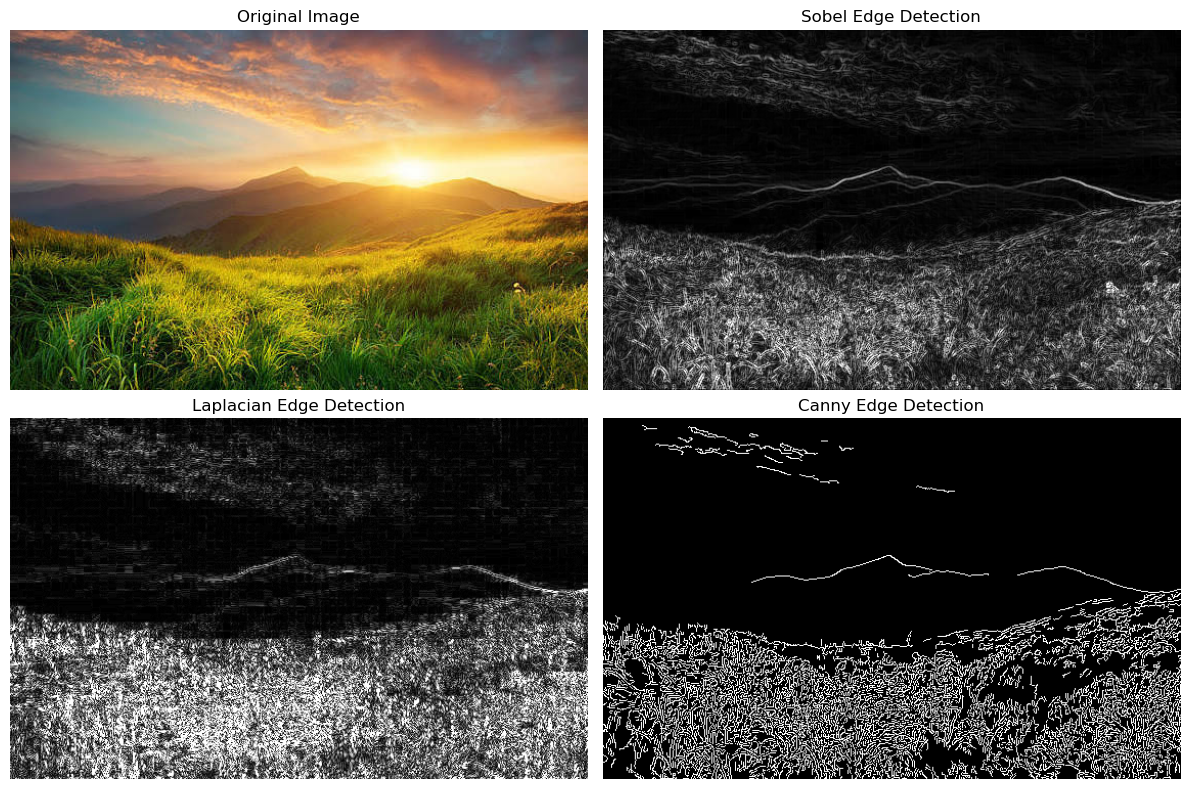

Analysis: Canny generally produces clearer and thinner edges.
Sobel detects directional gradients, while Laplacian detects rapid intensity changes.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("natural.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

sobel_x = cv2.convertScaleAbs(sobel_x)
sobel_y = cv2.convertScaleAbs(sobel_y)
sobel = cv2.addWeighted(sobel_x, 0.5, sobel_y, 0.5, 0)

laplacian = cv2.Laplacian(gray, cv2.CV_64F, ksize=3)
laplacian = cv2.convertScaleAbs(laplacian)

canny = cv2.Canny(gray, 100, 200)

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(sobel, cmap="gray")
plt.title("Sobel Edge Detection")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(laplacian, cmap="gray")
plt.title("Laplacian Edge Detection")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(canny, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Analysis: Canny generally produces clearer and thinner edges.")
print("Sobel detects directional gradients, while Laplacian detects rapid intensity changes.")

## Problem 2: Noise Sensitivity Experiment

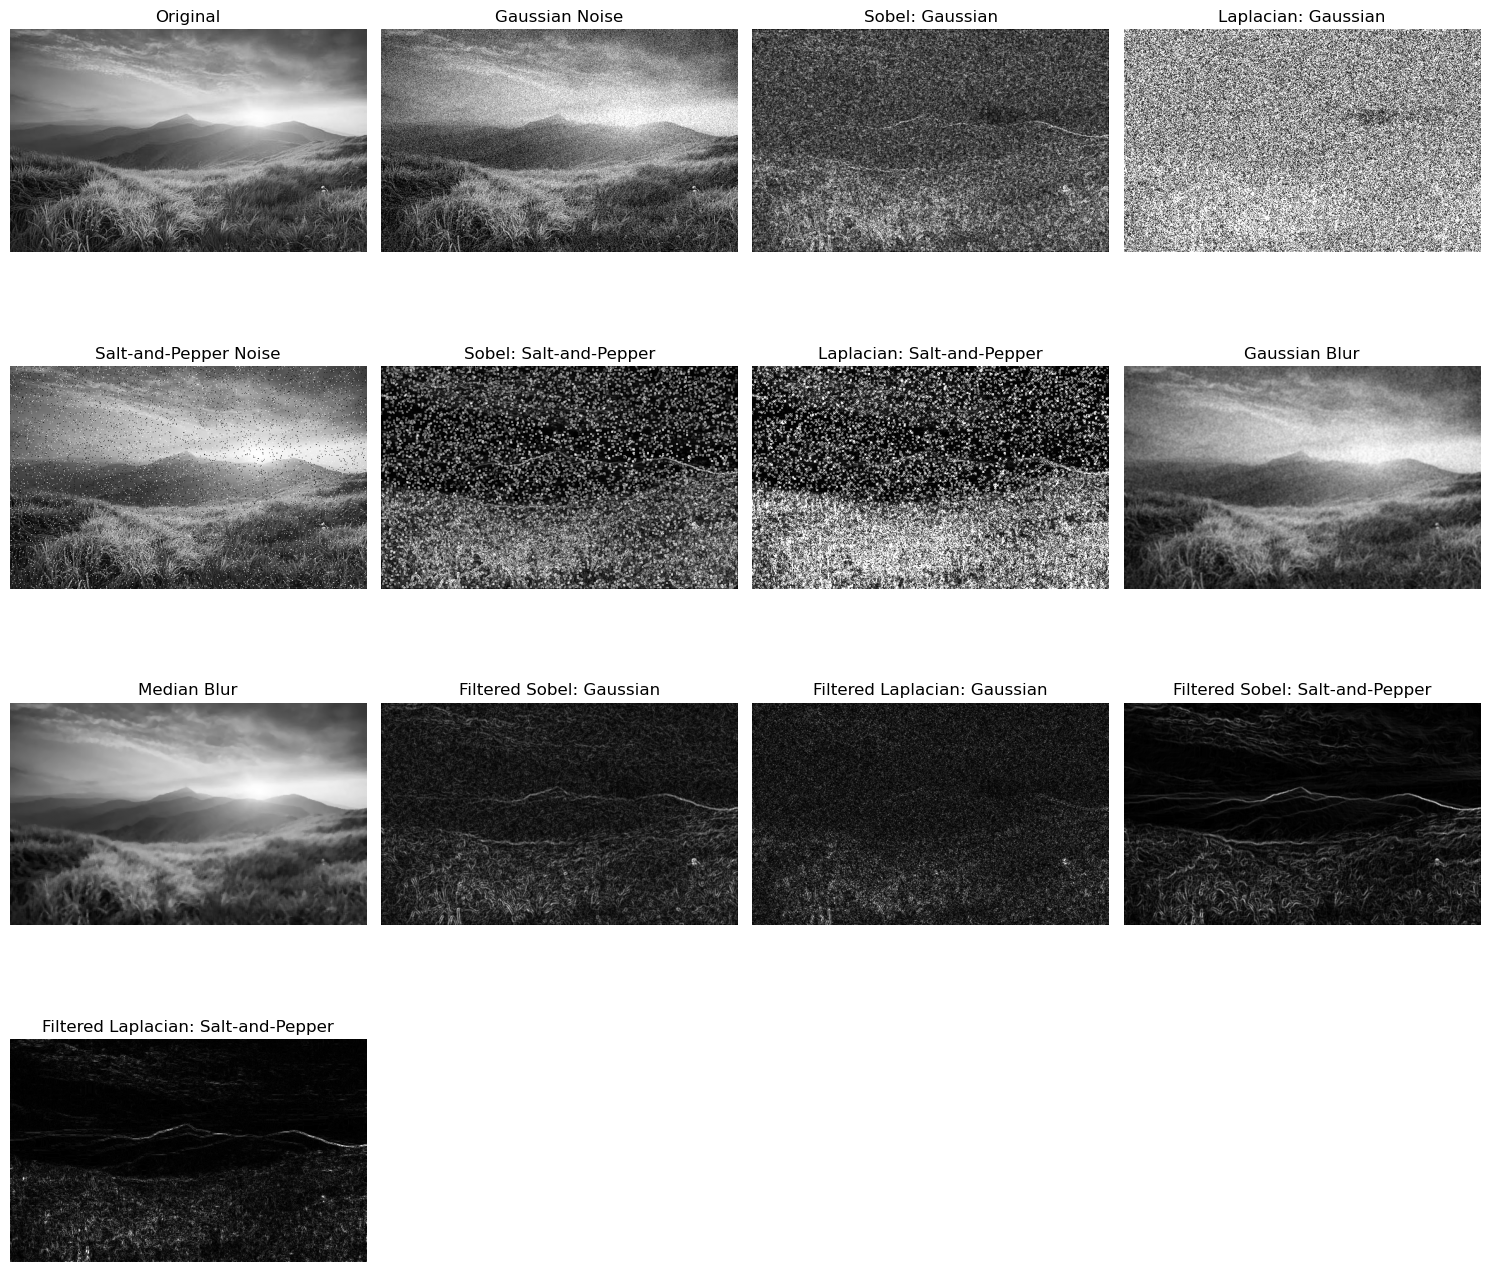

Laplacian is generally more sensitive to noise.
Gaussian blur helps reduce Gaussian noise.
Median filtering helps reduce salt-and-pepper noise.


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("natural.jpg", cv2.IMREAD_GRAYSCALE)

gaussian_noise = np.random.normal(0, 25, img.shape)
noisy_gaussian = np.clip(
    img.astype(np.float32) + gaussian_noise, 0, 255
).astype(np.uint8)

noisy_sp = img.copy()
prob = 0.05

random_values = np.random.random(img.shape)
noisy_sp[random_values < prob / 2] = 0
noisy_sp[random_values > 1 - prob / 2] = 255

def detect_edges(image):
    sobel_x = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)
    sobel = cv2.addWeighted(
        cv2.convertScaleAbs(sobel_x), 0.5,
        cv2.convertScaleAbs(sobel_y), 0.5, 0
    )

    laplacian = cv2.Laplacian(image, cv2.CV_64F, ksize=3)
    laplacian = cv2.convertScaleAbs(laplacian)

    return sobel, laplacian

sobel_gaussian, lap_gaussian = detect_edges(noisy_gaussian)
sobel_sp, lap_sp = detect_edges(noisy_sp)

gaussian_blur = cv2.GaussianBlur(noisy_gaussian, (5, 5), 1)
median_blur = cv2.medianBlur(noisy_sp, 5)

sobel_gaussian_filtered, lap_gaussian_filtered = detect_edges(gaussian_blur)
sobel_sp_filtered, lap_sp_filtered = detect_edges(median_blur)

images = [
    (img, "Original"),
    (noisy_gaussian, "Gaussian Noise"),
    (sobel_gaussian, "Sobel: Gaussian"),
    (lap_gaussian, "Laplacian: Gaussian"),
    (noisy_sp, "Salt-and-Pepper Noise"),
    (sobel_sp, "Sobel: Salt-and-Pepper"),
    (lap_sp, "Laplacian: Salt-and-Pepper"),
    (gaussian_blur, "Gaussian Blur"),
    (median_blur, "Median Blur"),
    (sobel_gaussian_filtered, "Filtered Sobel: Gaussian"),
    (lap_gaussian_filtered, "Filtered Laplacian: Gaussian"),
    (sobel_sp_filtered, "Filtered Sobel: Salt-and-Pepper"),
    (lap_sp_filtered, "Filtered Laplacian: Salt-and-Pepper")
]

plt.figure(figsize=(15, 14))

for i, (image, title) in enumerate(images, 1):
    plt.subplot(4, 4, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Laplacian is generally more sensitive to noise.")
print("Gaussian blur helps reduce Gaussian noise.")
print("Median filtering helps reduce salt-and-pepper noise.")

## Problem 3: Compression Ratio Comparison (RLE vs Huffman)

IMAGE INFORMATION
-----------------
Image dimensions: (353, 565)
Total pixels: 199445
Original size (bits): 1595560

RUN-LENGTH ENCODING (RLE)
-------------------------
Number of runs: 152339
Estimated compressed size (bits): 6093560
Percentage size reduction: -281.91 %

HUFFMAN CODING
--------------
Unique pixel values: 256
Compressed data size (bits): 1559645
Percentage size reduction: 2.25 %

COMPRESSION COMPARISON
----------------------
Method                    Bits       Reduction (%)
--------------------------------------------------
Original               1595560                0.00
RLE                    6093560             -281.91
Huffman                1559645                2.25

Note: Compressed sizes are estimates for the encoded data.
They exclude headers, tree storage, and file-format overhead.


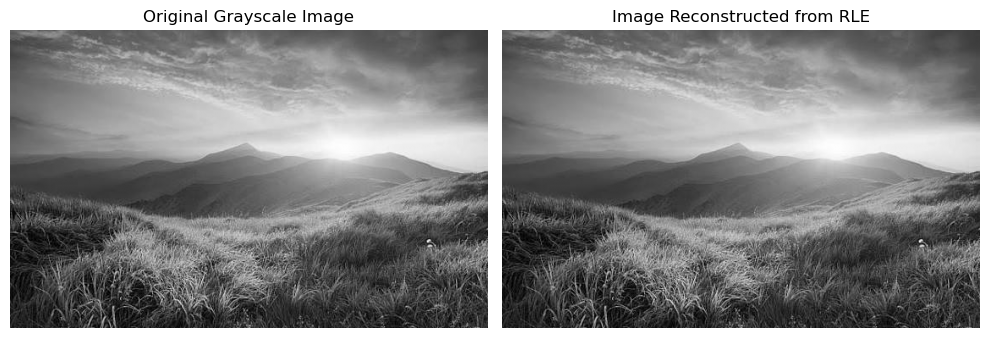

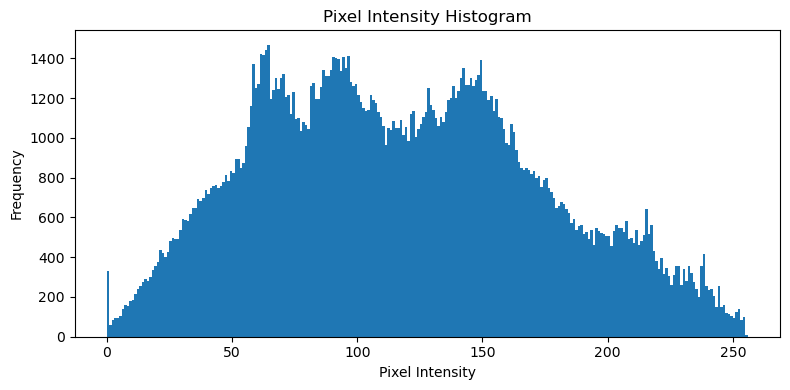

In [5]:

import cv2
import numpy as np
import heapq
import matplotlib.pyplot as plt
from collections import Counter

# --------------------------------------------------
# 1. Load the image in grayscale
# --------------------------------------------------
img = cv2.imread("natural.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError(
        "natural.jpg not found. Keep it in the same folder as this code."
    )

flat = img.flatten()

# Original image size: 8 bits per pixel
original_bits = len(flat) * 8

print("IMAGE INFORMATION")
print("-----------------")
print("Image dimensions:", img.shape)
print("Total pixels:", len(flat))
print("Original size (bits):", original_bits)


# --------------------------------------------------
# 2. Run-Length Encoding (RLE)
# --------------------------------------------------
rle = []

if len(flat) > 0:
    current_value = int(flat[0])
    count = 1

    for pixel in flat[1:]:
        pixel = int(pixel)

        if pixel == current_value:
            count += 1
        else:
            rle.append((current_value, count))
            current_value = pixel
            count = 1

    rle.append((current_value, count))

# Estimate storage using 8 bits for pixel value
# and 32 bits for run length per pair
rle_bits = len(rle) * (8 + 32)

rle_reconstructed = []
for value, count in rle:
    rle_reconstructed.extend([value] * count)

rle_reconstructed = np.array(
    rle_reconstructed, dtype=np.uint8
).reshape(img.shape)

rle_reduction = (
    (original_bits - rle_bits) / original_bits
) * 100

print("\nRUN-LENGTH ENCODING (RLE)")
print("-------------------------")
print("Number of runs:", len(rle))
print("Estimated compressed size (bits):", rle_bits)
print("Percentage size reduction:", round(rle_reduction, 2), "%")


# --------------------------------------------------
# 3. Huffman Coding
# --------------------------------------------------
frequency = Counter(int(pixel) for pixel in flat)

# Each heap node contains:
# [frequency, unique_id, node]
# A unique ID avoids comparison errors between nodes.
heap = []
unique_id = 0

for symbol, freq in frequency.items():
    heap.append([freq, unique_id, symbol])
    unique_id += 1

heapq.heapify(heap)

# Build the Huffman tree
while len(heap) > 1:
    freq1, id1, node1 = heapq.heappop(heap)
    freq2, id2, node2 = heapq.heappop(heap)

    merged_node = (node1, node2)

    heapq.heappush(
        heap,
        [freq1 + freq2, unique_id, merged_node]
    )
    unique_id += 1

# Generate Huffman codes
huffman_codes = {}

def generate_codes(node, code=""):
    if not isinstance(node, tuple):
        huffman_codes[node] = code if code else "0"
        return

    left, right = node
    generate_codes(left, code + "0")
    generate_codes(right, code + "1")

if heap:
    generate_codes(heap[0][2])

# Calculate encoded bit length without creating a huge string
huffman_bits = sum(
    frequency[symbol] * len(huffman_codes[symbol])
    for symbol in frequency
)

huffman_reduction = (
    (original_bits - huffman_bits) / original_bits
) * 100

print("\nHUFFMAN CODING")
print("--------------")
print("Unique pixel values:", len(frequency))
print("Compressed data size (bits):", huffman_bits)
print("Percentage size reduction:", round(huffman_reduction, 2), "%")


# --------------------------------------------------
# 4. Compare the compression results
# --------------------------------------------------
print("\nCOMPRESSION COMPARISON")
print("----------------------")
print(f"{'Method':<15}{'Bits':>15}{'Reduction (%)':>20}")
print("-" * 50)
print(f"{'Original':<15}{original_bits:>15}{0:>20.2f}")
print(f"{'RLE':<15}{rle_bits:>15}{rle_reduction:>20.2f}")
print(f"{'Huffman':<15}{huffman_bits:>15}{huffman_reduction:>20.2f}")

print("\nNote: Compressed sizes are estimates for the encoded data.")
print("They exclude headers, tree storage, and file-format overhead.")


# --------------------------------------------------
# 5. Display original and reconstructed images
# --------------------------------------------------
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rle_reconstructed, cmap="gray")
plt.title("Image Reconstructed from RLE")
plt.axis("off")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 6. Display pixel intensity histogram
# --------------------------------------------------
plt.figure(figsize=(8, 4))
plt.hist(flat, bins=256, range=(0, 256))
plt.title("Pixel Intensity Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.tight_layout()```python
import cv2
import numpy as np
import heapq
import matplotlib.pyplot as plt
from collections import Counter

# --------------------------------------------------
# 1. Load the grayscale image
# --------------------------------------------------
img = cv2.imread("natural.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError(
        "natural.jpg not found. Keep it in the same folder as this code."
    )

flat = img.flatten()
original_bits = flat.size * 8

print("IMAGE INFORMATION")
print("-----------------")
print("Image dimensions:", img.shape)
print("Total pixels:", flat.size)
print("Original bit length:", original_bits, "bits")
print("WHY: Each grayscale pixel is stored using 8 bits.")


# --------------------------------------------------
# 2. Run-Length Encoding (RLE)
# --------------------------------------------------
rle = []

if flat.size > 0:
    current_value = int(flat[0])
    count = 1

    for pixel in flat[1:]:
        pixel = int(pixel)

        if pixel == current_value and count < 2**32 - 1:
            count += 1
        else:
            rle.append((current_value, count))
            current_value = pixel
            count = 1

    rle.append((current_value, count))

# Each run stores an 8-bit pixel value and a 32-bit run length.
rle_bits = len(rle) * 40

rle_reconstructed = np.empty(flat.size, dtype=np.uint8)
position = 0

for value, count in rle:
    rle_reconstructed[position:position + count] = value
    position += count

rle_reconstructed = rle_reconstructed.reshape(img.shape)

rle_reduction = (
    (original_bits - rle_bits) / original_bits
) * 100

rle_ratio = original_bits / rle_bits

print("\nRUN-LENGTH ENCODING (RLE)")
print("-------------------------")
print("Number of runs:", len(rle))
print("Compressed bit length:", rle_bits)
print("Compression ratio:", round(rle_ratio, 3), ":1")
print("Percentage size reduction:", round(rle_reduction, 2), "%")

print("\nWHY RLE PERFORMED THIS WAY:")
if rle_bits < original_bits:
    print("RLE reduced the size because consecutive pixels with")
    print("identical intensities were represented as value-count pairs.")
    print("Fewer runs mean better compression.")
else:
    print("RLE increased the estimated size because the image contains")
    print("many changes in consecutive pixel intensities.")
    print("These changes create many short runs, each requiring 40 bits.")


# --------------------------------------------------
# 3. Huffman Coding
# --------------------------------------------------
frequency = Counter(int(pixel) for pixel in flat)

heap = []
unique_id = 0

for symbol, freq in frequency.items():
    heap.append([freq, unique_id, symbol])
    unique_id += 1

heapq.heapify(heap)

while len(heap) > 1:
    freq1, id1, node1 = heapq.heappop(heap)
    freq2, id2, node2 = heapq.heappop(heap)

    merged_node = (node1, node2)

    heapq.heappush(
        heap,
        [freq1 + freq2, unique_id, merged_node]
    )
    unique_id += 1

huffman_codes = {}

def generate_codes(node, code=""):
    if not isinstance(node, tuple):
        huffman_codes[node] = code if code else "0"
        return

    left, right = node
    generate_codes(left, code + "0")
    generate_codes(right, code + "1")

if heap:
    generate_codes(heap[0][2])

huffman_bits = sum(
    frequency[symbol] * len(huffman_codes[symbol])
    for symbol in frequency
)

huffman_reduction = (
    (original_bits - huffman_bits) / original_bits
) * 100

huffman_ratio = original_bits / huffman_bits

print("\nHUFFMAN CODING")
print("--------------")
print("Unique pixel values:", len(frequency))
print("Compressed bit length:", huffman_bits)
print("Compression ratio:", round(huffman_ratio, 3), ":1")
print("Percentage size reduction:", round(huffman_reduction, 2), "%")

print("\nWHY HUFFMAN CODING PERFORMED THIS WAY:")
print("Huffman coding assigns shorter binary codes to frequent")
print("pixel values and longer codes to less frequent values.")
print("Its performance depends on how unevenly pixel intensities")
print("are distributed in the image.")

if huffman_bits < original_bits:
    print("The encoded pixel data is smaller than the original")
    print("because the average code length is below 8 bits per pixel.")
else:
    print("The encoded pixel data is not smaller than the original.")
    print("The frequency distribution does not provide enough")
    print("benefit to beat the original 8-bit representation.")


# --------------------------------------------------
# 4. Compression Comparison
# --------------------------------------------------
methods = ["Original", "RLE", "Huffman"]
bit_lengths = [original_bits, rle_bits, huffman_bits]

reductions = [0, rle_reduction, huffman_reduction]

print("\nCOMPRESSION COMPARISON")
print("----------------------")
print(f"{'Method':<15}{'Bit Length':>15}{'Reduction (%)':>20}")
print("-" * 50)

for method, bits, reduction in zip(
    methods, bit_lengths, reductions
):
    print(f"{method:<15}{bits:>15}{reduction:>20.2f}")

print("\nFINAL ANALYSIS")
print("--------------")

if rle_bits < huffman_bits:
    print("RLE has a smaller estimated data size than Huffman coding.")
    print("This indicates that repeated consecutive pixel values")
    print("are particularly useful for compressing this image.")
elif huffman_bits < rle_bits:
    print("Huffman coding has a smaller encoded data size than RLE.")
    print("This indicates that pixel-value frequencies are more")
    print("useful for compression than consecutive repetitions.")
else:
    print("Both methods produce the same estimated data size.")

if min(rle_bits, huffman_bits) < original_bits:
    best_method = (
        "RLE" if rle_bits < huffman_bits else "Huffman"
    ) if rle_bits != huffman_bits else "Both methods"

    print("The better result among these methods is:", best_method)
else:
    print("Neither method reduces the estimated data size.")
    print("A natural image may not contain enough repeated runs")
    print("or frequency imbalance for these methods to be effective.")

print("\nLIMITATIONS")
print("-----------")
print("RLE size assumes 8 bits per value and 32 bits per run count.")
print("Huffman size includes encoded data bits only.")
print("Both estimates exclude headers, Huffman tree storage,")
print("and other file-format overhead.")


# --------------------------------------------------
# 5. Display Original and Reconstructed Images
# --------------------------------------------------
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rle_reconstructed, cmap="gray")
plt.title("RLE Reconstructed Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 6. Display Compression Comparison Graph
# --------------------------------------------------
plt.figure(figsize=(8, 5))
bars = plt.bar(methods, bit_lengths)

plt.ylabel("Bit Length")
plt.title("RLE vs Huffman Compression")

for bar, bits in zip(bars, bit_lengths):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bits:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 7. Display Pixel Intensity Histogram
# --------------------------------------------------
plt.figure(figsize=(8, 4))

plt.hist(flat, bins=256, range=(0, 256))

plt.title("Pixel Intensity Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()
```

plt.show()

## Problem 4: JPEG Block Artifact Analysis

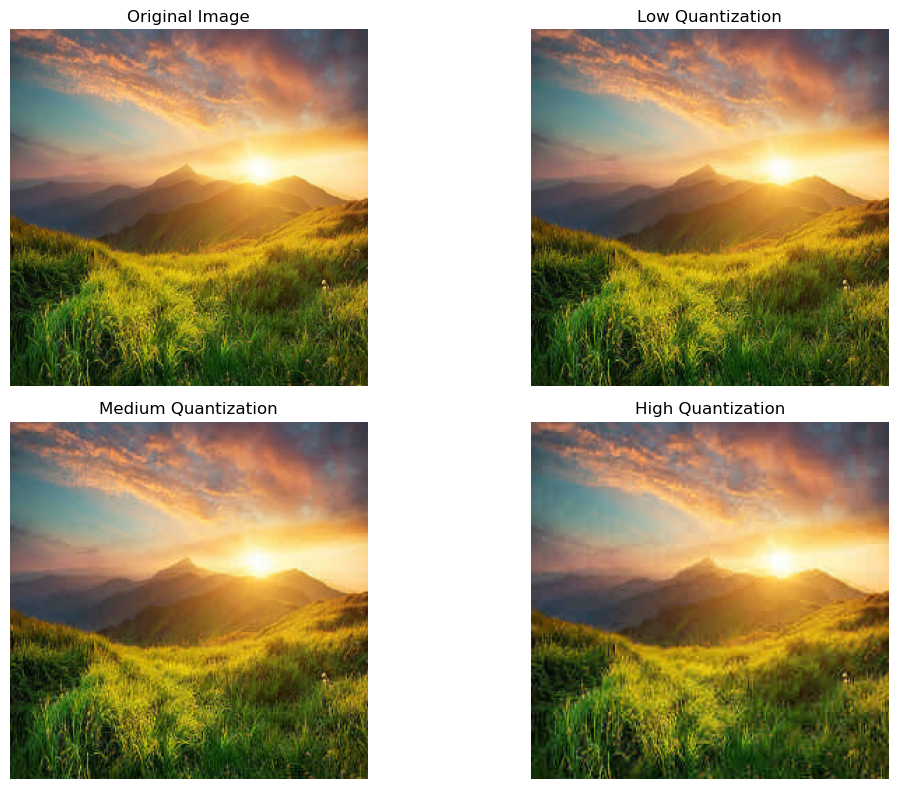

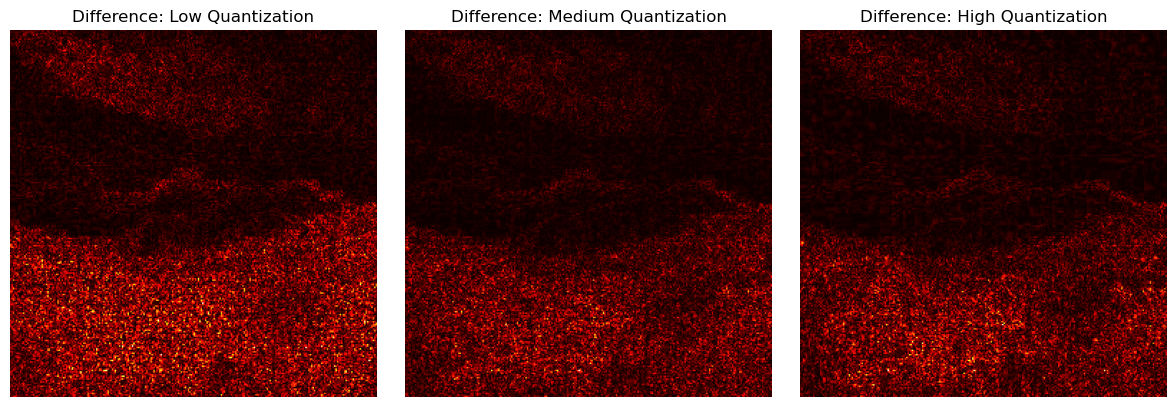

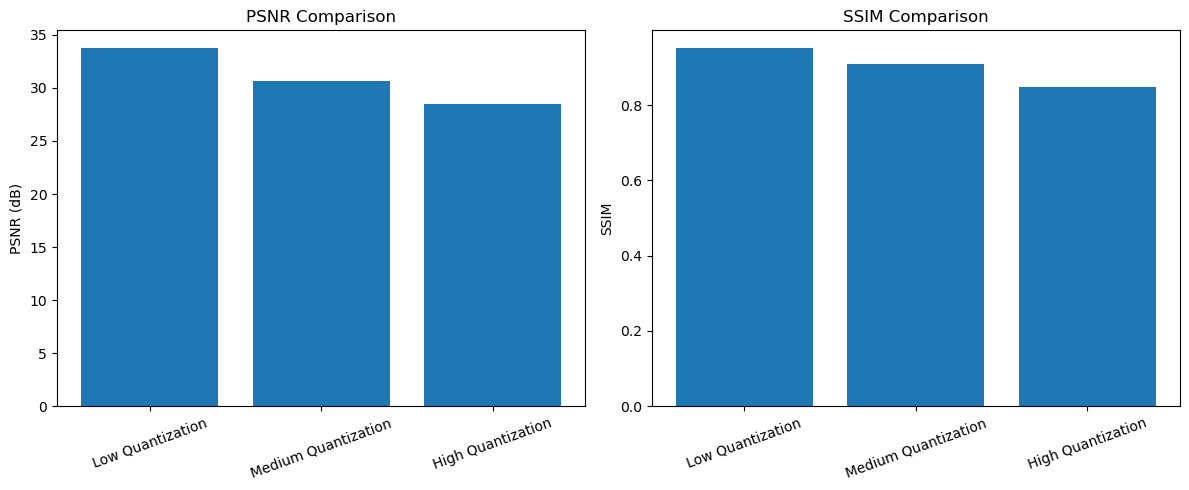

JPEG Block Artifact Analysis Results
--------------------------------------------------

Low Quantization
MSE  : 27.48
PSNR : 33.74 dB
SSIM : 0.9515

Medium Quantization
MSE  : 55.59
PSNR : 30.68 dB
SSIM : 0.9099

High Quantization
MSE  : 91.60
PSNR : 28.51 dB
SSIM : 0.8495


In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.fftpack import dct, idct
from skimage.metrics import structural_similarity as ssim

# Load image
image = cv2.imread("natural.jpg")

if image is None:
    raise FileNotFoundError("natural.jpg not found.")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image = cv2.resize(image, (256, 256))

# Convert to YCrCb color space
ycrcb = cv2.cvtColor(image, cv2.COLOR_RGB2YCrCb).astype(np.float32)
Y = ycrcb[:, :, 0]

# JPEG-style quantization matrix
Q = np.array([
    [16, 11, 10, 16, 24, 40, 51, 61],
    [12, 12, 14, 19, 26, 58, 60, 55],
    [14, 13, 16, 24, 40, 57, 69, 56],
    [14, 17, 22, 29, 51, 87, 80, 62],
    [18, 22, 37, 56, 68, 109, 103, 77],
    [24, 35, 55, 64, 81, 104, 113, 92],
    [49, 64, 78, 87, 103, 121, 120, 101],
    [72, 92, 95, 98, 112, 100, 103, 99]
], dtype=np.float32)


def dct2(block):
    return dct(dct(block.T, norm="ortho").T, norm="ortho")


def idct2(block):
    return idct(idct(block.T, norm="ortho").T, norm="ortho")


def jpeg_compress(channel, quality_factor):
    result = np.zeros_like(channel)
    quant_matrix = Q * quality_factor

    for i in range(0, channel.shape[0], 8):
        for j in range(0, channel.shape[1], 8):
            block = channel[i:i+8, j:j+8] - 128
            transformed = dct2(block)
            quantized = np.round(transformed / quant_matrix)
            dequantized = quantized * quant_matrix
            reconstructed = idct2(dequantized) + 128
            result[i:i+8, j:j+8] = reconstructed

    return np.clip(result, 0, 255)


# Compression at different quantization levels
quality_levels = {
    "Low Quantization": 0.5,
    "Medium Quantization": 1.0,
    "High Quantization": 2.0
}

compressed_images = {}
metrics = {}

for name, factor in quality_levels.items():
    compressed_Y = jpeg_compress(Y, factor)

    compressed_ycrcb = ycrcb.copy()
    compressed_ycrcb[:, :, 0] = compressed_Y

    compressed_rgb = cv2.cvtColor(
        np.clip(compressed_ycrcb, 0, 255).astype(np.uint8),
        cv2.COLOR_YCrCb2RGB
    )

    compressed_images[name] = compressed_rgb

    original_gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    compressed_gray = cv2.cvtColor(
        compressed_rgb, cv2.COLOR_RGB2GRAY
    )

    mse = np.mean(
        (original_gray.astype(np.float32) -
         compressed_gray.astype(np.float32)) ** 2
    )

    psnr = float("inf") if mse == 0 else 10 * np.log10(255**2 / mse)

    ssim_value = ssim(original_gray, compressed_gray, data_range=255)

    metrics[name] = {
        "MSE": mse,
        "PSNR": psnr,
        "SSIM": ssim_value
    }


# Display images
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

for index, (name, compressed) in enumerate(compressed_images.items(), start=2):
    plt.subplot(2, 2, index)
    plt.imshow(compressed)
    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()


# Display difference maps
original_gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(12, 4))

for index, (name, compressed) in enumerate(compressed_images.items(), start=1):
    compressed_gray = cv2.cvtColor(compressed, cv2.COLOR_RGB2GRAY)

    difference = cv2.absdiff(original_gray, compressed_gray)

    plt.subplot(1, 3, index)
    plt.imshow(difference, cmap="hot")
    plt.title(f"Difference: {name}")
    plt.axis("off")

plt.tight_layout()
plt.show()


# Display PSNR and SSIM
names = list(metrics.keys())
psnr_values = [metrics[name]["PSNR"] for name in names]
ssim_values = [metrics[name]["SSIM"] for name in names]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.bar(names, psnr_values)
plt.title("PSNR Comparison")
plt.ylabel("PSNR (dB)")
plt.xticks(rotation=20)

plt.subplot(1, 2, 2)
plt.bar(names, ssim_values)
plt.title("SSIM Comparison")
plt.ylabel("SSIM")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()


# Print results
print("JPEG Block Artifact Analysis Results")
print("-" * 50)

for name, values in metrics.items():
    print(f"\n{name}")
    print(f"MSE  : {values['MSE']:.2f}")
    print(f"PSNR : {values['PSNR']:.2f} dB")
    print(f"SSIM : {values['SSIM']:.4f}")

## Problem 5: Texture-Based Segmentation Using GLCM Feature

C:\Users\megha\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\megha\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\megha\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\megha\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

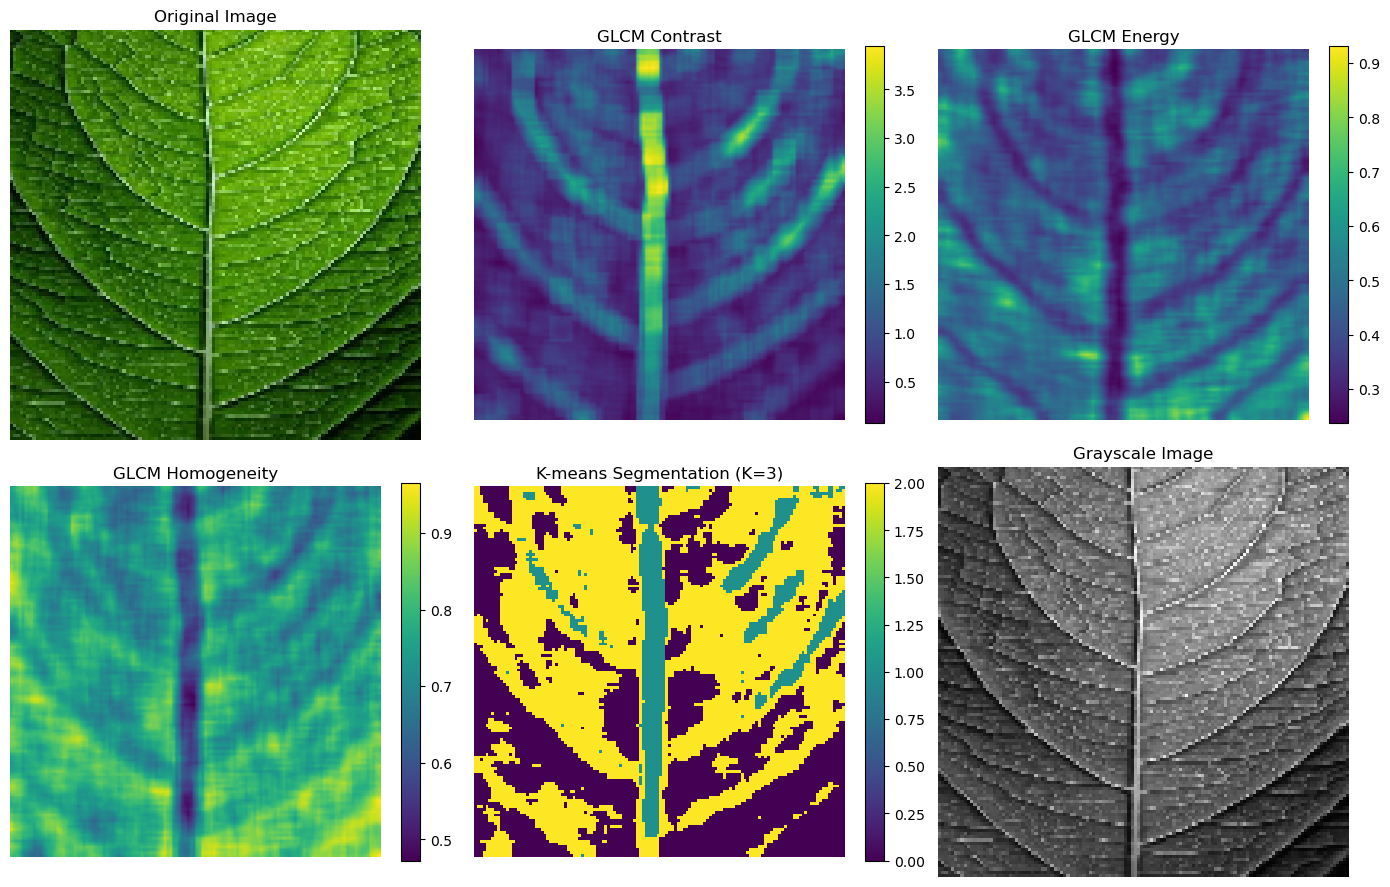

Texture-Based Segmentation Results
----------------------------------
Number of clusters: 3
Cluster 1: 6309 pixels (38.51%)
Cluster 2: 1587 pixels (9.69%)
Cluster 3: 8488 pixels (51.81%)

GLCM feature means by cluster:

Cluster 1
Mean Contrast: 0.5084
Mean Energy: 0.5431
Mean Homogeneity: 0.8223

Cluster 2
Mean Contrast: 2.5041
Mean Energy: 0.3267
Mean Homogeneity: 0.6255

Cluster 3
Mean Contrast: 1.0401
Mean Energy: 0.4153
Mean Homogeneity: 0.7294


In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load image
image = cv2.imread("texture.jpg")

if image is None:
    raise FileNotFoundError("texture.jpg not found.")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image = cv2.resize(image, (128, 128))

# Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Quantize grayscale image into 8 levels
gray_quantized = (gray // 32).astype(np.uint8)

# Initialize GLCM feature maps
height, width = gray_quantized.shape

contrast_map = np.zeros((height, width), dtype=np.float32)
energy_map = np.zeros((height, width), dtype=np.float32)
homogeneity_map = np.zeros((height, width), dtype=np.float32)

# Calculate local GLCM features
window_size = 9
pad = window_size // 2

padded = cv2.copyMakeBorder(
    gray_quantized,
    pad, pad, pad, pad,
    cv2.BORDER_REFLECT
)

for i in range(height):
    for j in range(width):
        window = padded[
            i:i + window_size,
            j:j + window_size
        ]

        glcm = graycomatrix(
            window,
            distances=[1],
            angles=[0],
            levels=8,
            symmetric=True,
            normed=True
        )

        contrast_map[i, j] = graycoprops(
            glcm, "contrast"
        )[0, 0]

        energy_map[i, j] = graycoprops(
            glcm, "energy"
        )[0, 0]

        homogeneity_map[i, j] = graycoprops(
            glcm, "homogeneity"
        )[0, 0]

# Create feature vectors
features = np.stack(
    [
        contrast_map.ravel(),
        energy_map.ravel(),
        homogeneity_map.ravel()
    ],
    axis=1
)

# Standardize features
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# Apply K-means clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(features_scaled)

# Reshape segmented labels
segmented_image = labels.reshape(height, width)

# Display results
plt.figure(figsize=(14, 9))

plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(contrast_map, cmap="viridis")
plt.title("GLCM Contrast")
plt.axis("off")
plt.colorbar(fraction=0.046)

plt.subplot(2, 3, 3)
plt.imshow(energy_map, cmap="viridis")
plt.title("GLCM Energy")
plt.axis("off")
plt.colorbar(fraction=0.046)

plt.subplot(2, 3, 4)
plt.imshow(homogeneity_map, cmap="viridis")
plt.title("GLCM Homogeneity")
plt.axis("off")
plt.colorbar(fraction=0.046)

plt.subplot(2, 3, 5)
plt.imshow(segmented_image, cmap="viridis", interpolation="nearest")
plt.title("K-means Segmentation (K=3)")
plt.axis("off")
plt.colorbar(fraction=0.046)

plt.subplot(2, 3, 6)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# Print cluster information
print("Texture-Based Segmentation Results")
print("----------------------------------")
print("Number of clusters:", kmeans.n_clusters)

for cluster in range(3):
    count = np.sum(labels == cluster)
    percentage = (count / len(labels)) * 100

    print(
        f"Cluster {cluster + 1}: "
        f"{count} pixels ({percentage:.2f}%)"
    )

print("\nGLCM feature means by cluster:")

for cluster in range(3):
    cluster_features = features[labels == cluster]

    print(f"\nCluster {cluster + 1}")
    print(f"Mean Contrast: {cluster_features[:, 0].mean():.4f}")
    print(f"Mean Energy: {cluster_features[:, 1].mean():.4f}")
    print(f"Mean Homogeneity: {cluster_features[:, 2].mean():.4f}")

## Problem 6: Multi-Feature Segmentation for Disease Detection

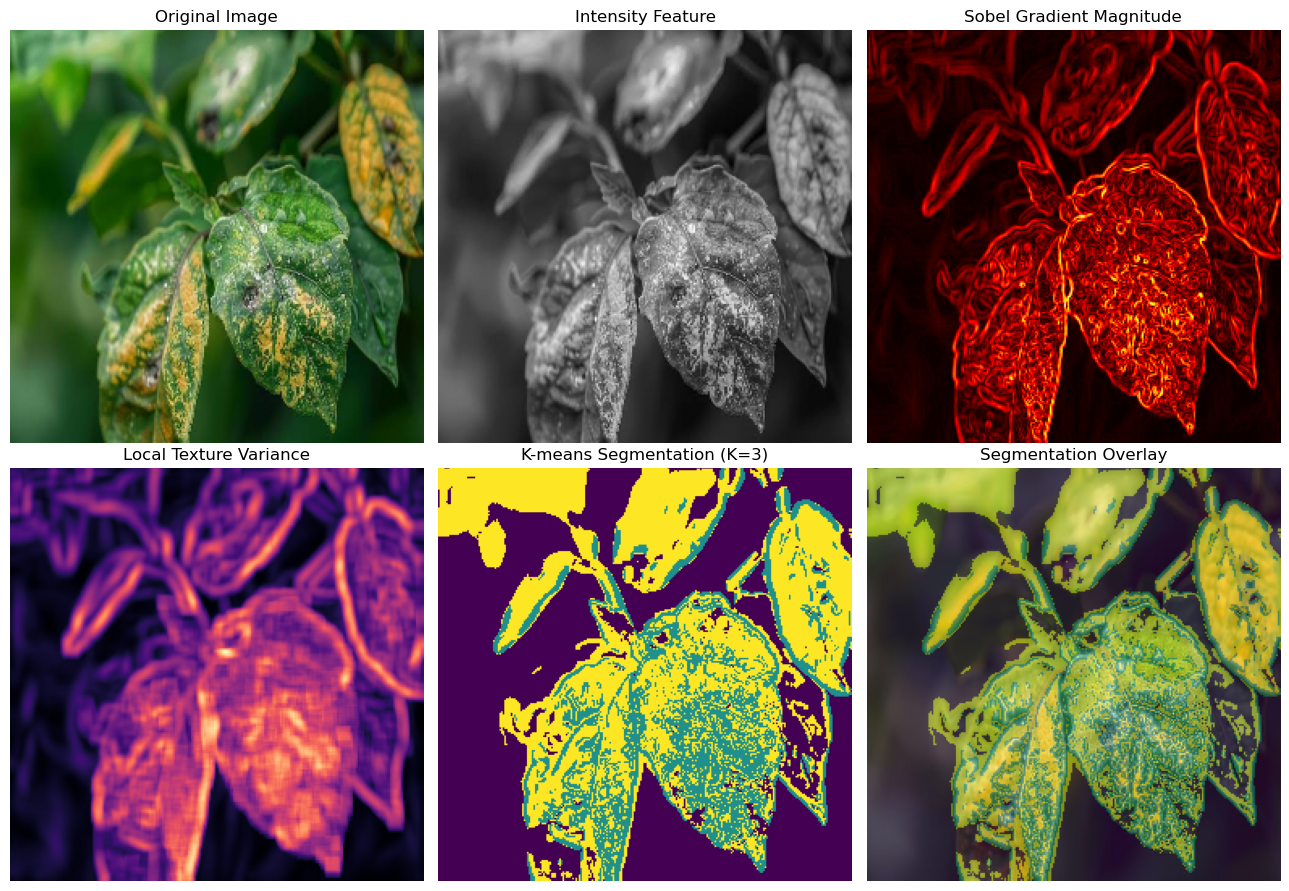

Multi-Feature Segmentation Results
----------------------------------
Number of clusters: 3

Cluster 1
Pixels: 30333
Percentage: 46.28%
Mean intensity: 0.2085
Mean gradient: 0.0355
Mean texture variance: 0.1449

Cluster 2
Pixels: 11365
Percentage: 17.34%
Mean intensity: 0.4083
Mean gradient: 0.3383
Mean texture variance: 0.5995

Cluster 3
Pixels: 23838
Percentage: 36.37%
Mean intensity: 0.4782
Mean gradient: 0.1179
Mean texture variance: 0.3926


In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load image
image = cv2.imread("leaf_disease.jpg")

if image is None:
    raise FileNotFoundError("leaf_disease.jpg not found.")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image = cv2.resize(image, (256, 256))

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Feature 1: Intensity
intensity = gray.astype(np.float32) / 255.0

# Feature 2: Sobel gradient magnitude
sobel_x = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)

gradient = np.sqrt(sobel_x**2 + sobel_y**2)
gradient = gradient / (gradient.max() + 1e-8)

# Feature 3: Local texture variance
gray_float = gray.astype(np.float32)

local_mean = cv2.blur(gray_float, (9, 9))
local_mean_square = cv2.blur(gray_float**2, (9, 9))

variance = np.maximum(
    local_mean_square - local_mean**2, 0
)

texture_variance = np.sqrt(variance)
texture_variance = texture_variance / (
    texture_variance.max() + 1e-8
)

# Combine features
features = np.stack(
    [
        intensity.ravel(),
        gradient.ravel(),
        texture_variance.ravel()
    ],
    axis=1
)

# Standardize features
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# Apply K-means clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(features_scaled)

# Reshape segmentation result
segmented = labels.reshape(gray.shape)

# Create a colored segmentation map
segmented_color = (
    plt.get_cmap("viridis")(
        segmented / 2.0
    )[:, :, :3] * 255
).astype(np.uint8)

# Display results
plt.figure(figsize=(13, 9))

plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(intensity, cmap="gray")
plt.title("Intensity Feature")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(gradient, cmap="hot")
plt.title("Sobel Gradient Magnitude")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(texture_variance, cmap="magma")
plt.title("Local Texture Variance")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(segmented_color)
plt.title("K-means Segmentation (K=3)")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(image)
plt.imshow(segmented, cmap="viridis", alpha=0.45)
plt.title("Segmentation Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

# Print cluster statistics
print("Multi-Feature Segmentation Results")
print("----------------------------------")
print("Number of clusters:", kmeans.n_clusters)

for cluster in range(3):
    mask = labels == cluster
    count = np.sum(mask)
    percentage = count / len(labels) * 100

    print(f"\nCluster {cluster + 1}")
    print(f"Pixels: {count}")
    print(f"Percentage: {percentage:.2f}%")
    print(f"Mean intensity: {features[mask, 0].mean():.4f}")
    print(f"Mean gradient: {features[mask, 1].mean():.4f}")
    print(f"Mean texture variance: {features[mask, 2].mean():.4f}")